In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import machine_learning_models as mlm
pd.set_option('display.max_rows', 100)

In [2]:
df = pd.read_csv(r'C:\Users\mechz\Documents\Jobs_Analysis\job_postings.csv')
X = df.drop(columns=['salary_year_avg'])
predictors = X.columns.to_list()
numerical_columns = ['job_posted_year', 'job_posted_month_sine']
numerical_indices = X.columns.get_indexer(numerical_columns)
X = X.to_numpy()
y = np.where(df['salary_year_avg'] > df['salary_year_avg'].median(), 1, 0)

training_index, testing_index = mlm.train_test_split(X.shape[0], 10000)
X_training = X[training_index]
y_training = y[training_index]
X_testing = X[testing_index]
y_testing = y[testing_index]

for index in numerical_indices:
    mean = np.mean(X_training[:,index])
    std = np.std(X_training[:, index])
    X_training[:,index] = (X_training[:,index] - mean) / std
    X_testing[:,index] = (X_testing[:,index] - mean) / std

special_groups = [[i for i, name in enumerate(predictors) if name.startswith('job_title_short_')], [i for i, name in enumerate(predictors) if name.startswith('job_country_')], [i for i, name in enumerate(predictors) if name.startswith('job_via_')]]
continuous_predictors = [i for i, name in enumerate(predictors) if name.startswith('job_posted_')]
indices_in_special_groups = [c for g in special_groups for c in g]
groups = special_groups + [[i] for i in range(X.shape[1]) if i not in indices_in_special_groups]
groups = sorted(groups, key=min)

print(f'The mean, median, and standard deviation of the salary are {np.mean(df['salary_year_avg']):.3f}, {np.median(df['salary_year_avg']):.3f}, and {np.std(df['salary_year_avg']):.3f} respectively.')

The mean, median, and standard deviation of the salary are 122390.906, 115000.000, and 47019.486 respectively.


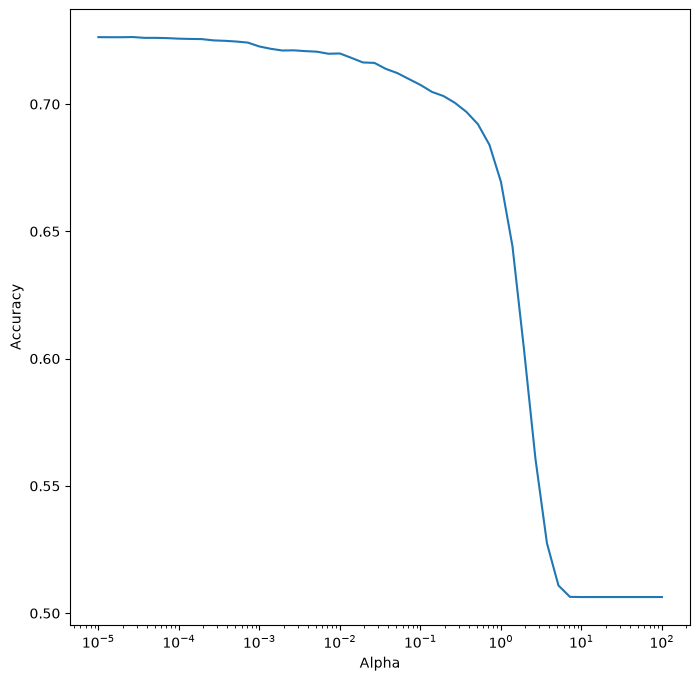

The best alpha value is 0.000 which gives a testing accuracy score of 73.450%.


,parameters,permutation_importance,direction
variables,,,
job_title_short_Senior Data Scientist,1.367298,6.93,28.19
job_title_short_Senior Data Engineer,1.054215,6.93,22.34
job_title_short_Software Engineer,0.433142,6.93,8.84
job_title_short_Data Scientist,0.393613,6.93,7.91
job_title_short_Data Engineer,0.197357,6.93,3.25
job_title_short_Machine Learning Engineer,0.119116,6.93,1.37
job_title_short_Cloud Engineer,-0.048241,6.93,-2.67
job_title_short_Senior Data Analyst,-0.376700,6.93,-10.56
job_title_short_Business Analyst,-1.183592,6.93,-28.19


In [3]:
alphas = np.logspace(-5, 2, 50)
accuracies = {}
for alpha in alphas:
    accuracies_one_fold = []
    for fold in mlm.kfold_cross_validation(5, X_training.shape[0]):
        inner_model = mlm.Logistic_Regression(alpha=alpha)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
        accuracy = np.sum(predictions == y_training[fold]) / len(y_training[fold])
        accuracies_one_fold.append(accuracy)
    average_accuracy = np.mean(accuracies_one_fold)
    accuracies.update({alpha:average_accuracy})
best_alpha = max(accuracies, key=accuracies.get)

fig, ax = plt.subplots(figsize=(8,8))
ax.semilogx(accuracies.keys(), accuracies.values())
ax.set_xlabel('Alpha')
ax.set_ylabel('Accuracy')
plt.show()

model = mlm.Logistic_Regression(alpha=best_alpha, max_iterations=10000)
model.fit(X_training, y_training)
predictions = model.predict(X_testing)
predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
accuracy = np.sum(predictions == y_testing) / len(y_testing)
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best alpha value is {best_alpha:.3f} which gives a testing accuracy score of {accuracy:.3%}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'parameters':model.parameters.reshape(-1), 'permutation_importance':np.round(model.permutation_importances(X_testing, y_testing, groups) * 100, 2), 'direction':np.round(model.marginal_importance(X_testing, y_testing, groups, continuous_predictors) * 100, 2)}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by=['permutation_importance', 'direction'], ascending=False).set_index('variables', drop=True)
display(parameters_df)

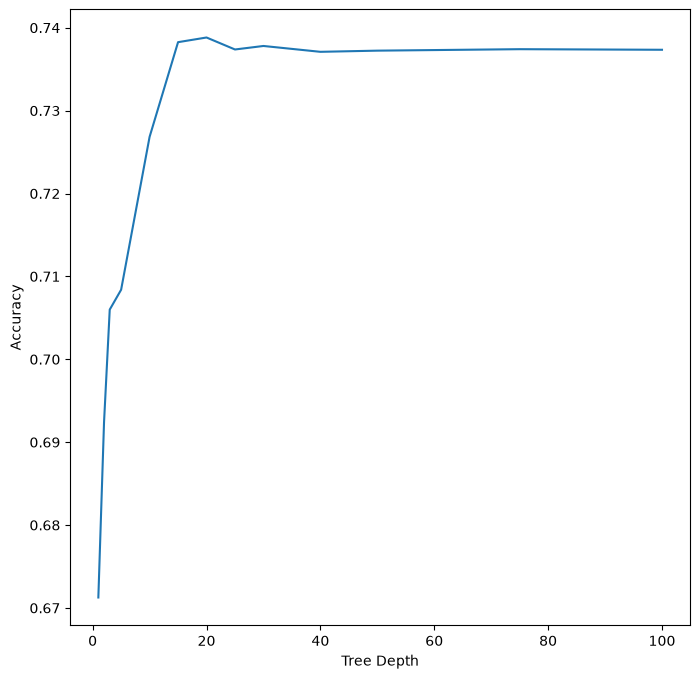

The best tree depth is 20 which gives a testing accuracy score of 75.220%.


,permutation_importance,gini_importance,direction
variables,,,
job_title_short_Data Analyst,5.74,36.19,-28.00
job_title_short_Business Analyst,5.74,5.95,-24.71
job_title_short_Senior Data Analyst,5.74,3.52,-12.76
job_title_short_Senior Data Scientist,5.74,1.13,20.20
job_title_short_Data Engineer,5.74,1.03,2.57
job_title_short_Data Scientist,5.74,0.95,4.99
job_title_short_Senior Data Engineer,5.74,0.63,18.19
job_title_short_Software Engineer,5.74,0.38,6.53
job_title_short_Machine Learning Engineer,5.74,0.31,7.45


In [4]:
depths = [1, 2, 3, 5, 10, 15, 20, 25, 30, 40, 50, 75, 100]
accuracies = []
for depth in depths:
    accuracies_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Classification_Tree(X.shape[1], max_depth=depth)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold))
        predictions = inner_model.predict(X_training[fold])
        predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
        accuracy = np.sum(predictions == y_training[fold]) / len(y_training[fold])
        accuracies_one_fold.append(accuracy)
    accuracies.append(np.mean(accuracies_one_fold))
highest_accuracy = max(accuracies)
best_depth = depths[accuracies.index(highest_accuracy)]

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(depths, accuracies)
ax.set_xlabel('Tree Depth')
ax.set_ylabel('Accuracy')
plt.show()

model = mlm.Classification_Tree(X.shape[1], max_depth=best_depth)
model.fit(X_training, y_training)
predictions = model.predict(X_testing)
predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
accuracy = np.sum(predictions == y_testing) / len(y_testing)
print(f'The best tree depth is {best_depth} which gives a testing accuracy score of {accuracy:.3%}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(model.permutation_importances(X_testing, y_testing, groups) * 100, 2), 'gini_importance':np.round(model.feature_importances() * 100, 2), 'direction':np.round(model.marginal_importance(X_testing, y_testing, groups, continuous_predictors) * 100, 2)}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by=['permutation_importance', 'gini_importance'], ascending=False).set_index('variables', drop=True)
display(parameters_df)

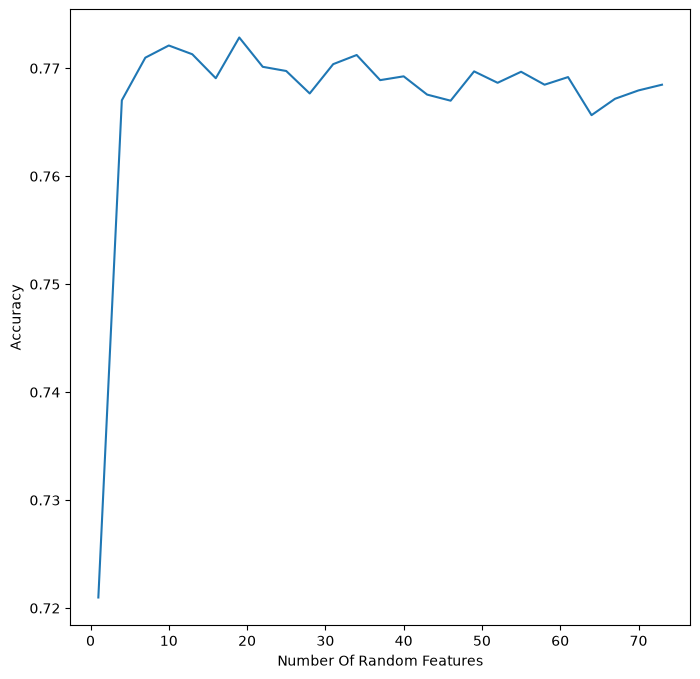

The best number of random features is 19 which gives a testing accuracy of 79.220%.


,permutation_importance,gini_importance,direction
variables,,,
job_title_short_Data Analyst,5.16,14.53,-26.29
job_title_short_Senior Data Scientist,5.16,2.70,21.99
job_title_short_Business Analyst,5.16,1.81,-18.26
job_title_short_Senior Data Engineer,5.16,1.77,21.69
job_title_short_Data Scientist,5.16,1.51,4.51
job_title_short_Data Engineer,5.16,1.40,1.33
job_title_short_Senior Data Analyst,5.16,1.04,-7.11
job_title_short_Software Engineer,5.16,0.45,-0.61
job_title_short_Machine Learning Engineer,5.16,0.29,3.22


In [5]:
random_feature_numbers = np.unique(np.linspace(1, X_training.shape[1], 25).astype(np.int32))
accuracies = []
for random_feature_number in random_feature_numbers:
    accuracies_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Classification_Random_Forest(number_of_trees=25, number_of_random_features=random_feature_number)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
        accuracy = np.sum(predictions == y_training[fold]) / len(y_training[fold])
        accuracies_one_fold.append(accuracy)
    accuracies.append([np.mean(accuracies_one_fold), random_feature_number])
accuracies = np.array(accuracies)
row_number = np.argmax(accuracies[:, 0])
best_random_feature_number = int(accuracies[row_number, 1])

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(accuracies[:, 1], accuracies[:, 0])
ax.set_xlabel('Number Of Random Features')
ax.set_ylabel('Accuracy')
plt.show()

model = mlm.Classification_Random_Forest(number_of_trees=500, number_of_random_features=best_random_feature_number)
model.fit(X_training, y_training)
predictions = model.predict(X_testing)
predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
accuracy = np.sum(predictions == y_testing) / len(y_testing)
print(f'The best number of random features is {best_random_feature_number} which gives a testing accuracy of {accuracy:.3%}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(model.permutation_importances(X_testing, y_testing, groups) * 100, 2), 'gini_importance':np.round(model.feature_importances() * 100, 2), 'direction':np.round(model.marginal_importance(X_testing, y_testing, groups, continuous_predictors) * 100, 2)}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by=['permutation_importance', 'gini_importance'], ascending=False).set_index('variables', drop=True)
display(parameters_df)

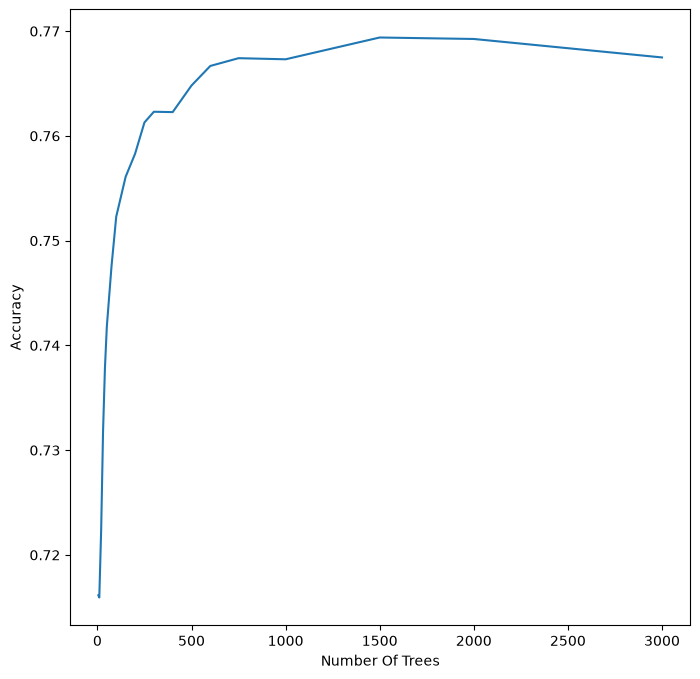

The best number of trees is 1500 which gives a testing accuracy of 76.740%.


,permutation_importance,gini_importance,direction
variables,,,
job_via_Ladders,2.89,2.59,-1.94
job_via_LinkedIn,2.89,2.09,8.63
job_via_Get.It,2.89,1.95,-3.66
job_via_BeBee,2.89,1.68,-17.52
job_via_Ai-Jobs.net,2.89,1.22,9.75
job_via_other,2.89,1.19,3.28
job_via_Indeed,2.89,0.49,-5.30
job_via_ZipRecruiter,2.89,0.46,-3.70
job_via_Built In,2.89,0.43,4.05


In [3]:
number_of_trees = [5, 10, 20, 30, 40, 50, 75, 100, 150, 200, 250, 300, 400, 500, 600, 750, 1000, 1500, 2000, 3000]
accuracies = []
for tree_number in number_of_trees:
    accuracies_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Classification_Gradient_Boosting(number_of_trees=tree_number)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        predictions = [1 if x > 0.5 else 0 for x in predictions]
        accuracy = np.sum(y_training[fold] == predictions) / len(y_training[fold])
        accuracies_one_fold.append(accuracy)
    accuracies.append([np.mean(accuracies_one_fold), tree_number])
accuracies = np.array(accuracies)
row_number = np.argmax(accuracies[:, 0])
best_tree_number = int(accuracies[row_number, 1])

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(accuracies[:, 1], accuracies[:, 0])
ax.set_xlabel('Number Of Trees')
ax.set_ylabel('Accuracy')
plt.show()

model = mlm.Classification_Gradient_Boosting(number_of_trees=best_tree_number)
model.fit(X_training, y_training)
predictions = model.predict(X_testing)
predictions = [1 if x > 0.5 else 0 for x in predictions]
accuracy = np.sum(y_testing == predictions) / len(y_testing)
print(f'The best number of trees is {best_tree_number} which gives a testing accuracy of {accuracy:.3%}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(model.permutation_importances(X_testing, y_testing, groups) * 100, 2), 'gini_importance':np.round(model.feature_importances() * 100, 2), 'direction':np.round(model.marginal_importance(X_testing, y_testing, groups, continuous_predictors) * 100, 2)}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by=['permutation_importance', 'gini_importance'], ascending=False).set_index('variables', drop=True)
display(parameters_df)

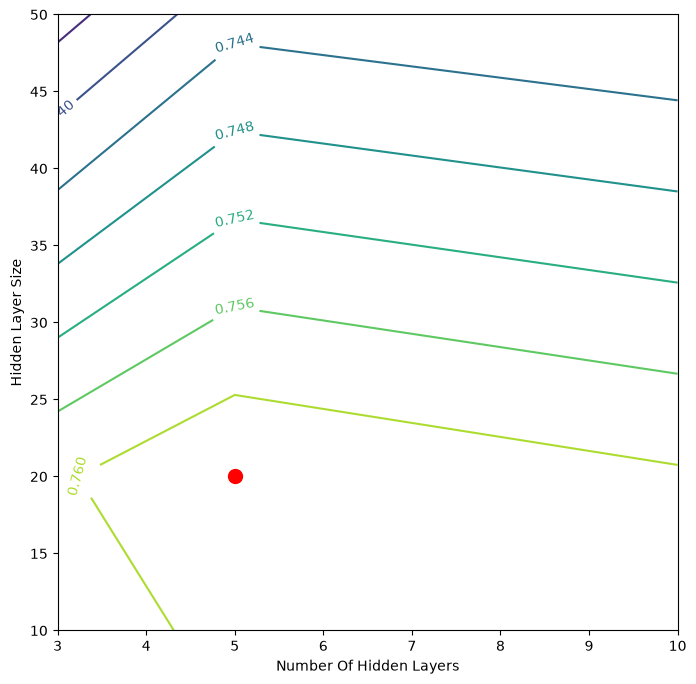

The best number of hidden layers is 5, the best hidden layer size is 20, the best patience is 1000, and the best weight decay is 0 giving a testing accuracy of 75.880%.


,permutation_importance,direction
variables,,
job_title_short_Cloud Engineer,5.53,3.07
job_title_short_Senior Data Scientist,5.53,26.03
job_title_short_Software Engineer,5.53,3.36
job_title_short_Data Analyst,5.53,-30.60
job_title_short_Data Engineer,5.53,-0.35
job_title_short_Data Scientist,5.53,5.15
job_title_short_Machine Learning Engineer,5.53,4.17
job_title_short_Senior Data Analyst,5.53,-10.94
job_title_short_Senior Data Engineer,5.53,22.47


In [4]:
hidden_layer_numbers = [3, 5, 10]
hidden_sizes = [10, 20, 50]
patiences = [50, 100, 1000]
weight_decays = [0, 0.01, 0.1]
accuracies = np.zeros((len(hidden_layer_numbers), len(hidden_sizes), len(patiences), len(weight_decays)))

for i, hidden_layer_number in enumerate(hidden_layer_numbers):
    for j, hidden_size in enumerate(hidden_sizes):
        for k, patience in enumerate(patiences):
            for l, weight_decay in enumerate(weight_decays):
                accuracies_one_fold = []
                for fold in mlm.kfold_cross_validation(5, len(y_training)):
                    inner_model = mlm.Classification_Neural_Network(hidden_layer_number, hidden_size, epochs=patience, weight_decay=weight_decay)
                    inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
                    predictions = inner_model.predict(X_training[fold])
                    predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
                    accuracy = np.sum(predictions == y_training[fold]) / len(y_training[fold])
                    accuracies_one_fold.append(accuracy)
                accuracies[i, j, k, l] = np.mean(accuracies_one_fold)
best_coords = np.argmax(accuracies)
best_coords = np.unravel_index(best_coords, accuracies.shape)
best_hidden_layer_number = hidden_layer_numbers[best_coords[0]]
best_hidden_size = hidden_sizes[best_coords[1]]
best_patience = patiences[best_coords[2]]
best_weight_decay = weight_decays[best_coords[3]]

fig, ax = plt.subplots(figsize=(8, 8))
plot = ax.contour(hidden_layer_numbers, hidden_sizes, accuracies[:, :, best_coords[2], best_coords[3]])
ax.set_xlabel('Number Of Hidden Layers')
ax.set_ylabel('Hidden Layer Size')
plt.plot(best_hidden_layer_number, best_hidden_size, marker='o', markersize=10, color='red')
plot.clabel()
plt.show()

model = mlm.Classification_Neural_Network(best_hidden_layer_number, best_hidden_size, epochs=best_patience, weight_decay=best_weight_decay)
model.fit(X_training, y_training)
predictions = model.predict(X_testing)
predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
accuracy = np.sum(predictions == y_testing) / len(y_testing)
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best number of hidden layers is {best_hidden_layer_number}, the best hidden layer size is {best_hidden_size}, the best patience is {best_patience}, and the best weight decay is {best_weight_decay} giving a testing accuracy of {accuracy:.3%}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(model.permutation_importances(X_testing, y_testing, groups) * 100, 2), 'direction':np.round(model.marginal_importance(X_testing, y_testing, groups, continuous_predictors) * 100, 2)}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='permutation_importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)